# ✈️ Prédire les retards d'avion

**Objectif :** prédire, **au moment de la réservation**, si un vol intérieur américain arrivera avec **plus de 15 minutes de retard**, et comprendre quels facteurs comptent le plus.

**Pourquoi c'est utile dans le voyage :** une agence, un comparateur ou une compagnie peut afficher un « risque de retard » à côté d'un vol, proposer des correspondances plus longues quand le risque est élevé, ou anticiper la charge du service client.

**Données :** [2015 Flight Delays and Cancellations](https://www.kaggle.com/datasets/usdot/flight-delays) (U.S. Department of Transportation), environ 5,8 millions de vols intérieurs américains en 2015.

**Plan :**
1. Chargement et nettoyage des données
2. Analyse exploratoire
3. Feature engineering (dont les taux de retard historiques sans fuite)
4. Séparation temporelle entraînement / validation / test
5. Modèles : référence naïve, régression logistique, LightGBM
6. Évaluation et choix du seuil
7. Interprétation : importance des variables et SHAP
8. Analyse des erreurs
9. Prédire le retard d'un vol
10. Conclusion

> Le code réutilisable est dans `src/features.py` (préparation) et `src/evaluation.py` (métriques et graphiques) ; ce notebook raconte l'histoire et affiche les résultats.

In [1]:
import os, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
import features as F
import evaluation as E

SEED = 42
pd.set_option("display.max_columns", 40)
E.style_graphiques()

## 1. Chargement et nettoyage des données

**Paramètres.** `DATA_DIR = None` cherche d'abord `flights.csv` dans le dossier `data/` du projet, puis le télécharge automatiquement avec `kagglehub`. L'ordinateur visé (Mac M2, 8 Go) ne permet pas de tout garder confortablement en mémoire : on travaille sur un **échantillon aléatoire de 1 500 000 vols** (modifiable), avec des types compacts (`int8`, `int16`, `category`).

In [2]:
DATA_DIR = None          # None = data/ puis téléchargement Kaggle ; sinon, chemin du dossier contenant flights.csv
SAMPLE_SIZE = 1_500_000  # nombre de vols gardés (None = tous, mais plus lent et plus de mémoire)

DATA_DIR = F.trouver_donnees(DATA_DIR)
airlines = pd.read_csv(f"{DATA_DIR}/airlines.csv").set_index("IATA_CODE")["AIRLINE"]
print("Données :", DATA_DIR.replace(os.path.expanduser("~"), "~"))

Données : ~/.cache/kagglehub/datasets/usdot/flight-delays/versions/1


### Ce que fait `charger_vols`

1. **Lecture sélective.** On ne lit que les colonnes connues à l'avance (horaires prévus, compagnie, aéroports, distance, durée prévue), plus la cible `ARRIVAL_DELAY` et les indicateurs d'annulation.
2. **Correction d'octobre 2015.** Ce mois-là, les aéroports sont codés par un identifiant numérique du DOT (« 12478 ») au lieu du code à 3 lettres (« JFK »). Au lieu de jeter tout le mois, on **reconstruit la correspondance** : un vol régulier (même compagnie, même numéro de vol, même heure, même distance) relie les mêmes aéroports en septembre, octobre et novembre. Chaque appariement est un « vote », et on garde le code majoritaire s'il obtient au moins 90 % des votes.
3. **Trafic prévu** (`TRAFIC_HEURE`) : nombre de départs programmés depuis l'aéroport dans la même heure. Il est calculé sur le **programme complet** (vols annulés compris, car ils étaient prévus) et **avant l'échantillonnage**, sinon on sous-estimerait le trafic d'un facteur 4.
4. **Nettoyage :** on retire les vols **annulés** ou **déroutés**, qui n'ont pas de retard à l'arrivée.
5. **Cible :** `RETARD = 1` si le vol arrive avec **plus de 15 minutes** de retard (définition officielle aux États-Unis).

> ⚠️ **Fuite de données (data leakage).** Le fichier contient aussi `DEPARTURE_DELAY`, `DEPARTURE_TIME`, `TAXI_OUT`, `WHEELS_OFF`, `AIR_TIME`, `ELAPSED_TIME`, `ARRIVAL_TIME` et les causes de retard (`WEATHER_DELAY`, `LATE_AIRCRAFT_DELAY`, `AIR_SYSTEM_DELAY`, `SECURITY_DELAY`, `AIRLINE_DELAY`). Ces valeurs ne sont connues **que pendant ou après le vol**. Par exemple, un vol parti avec 40 minutes de retard arrivera presque sûrement en retard : avec `DEPARTURE_DELAY`, on obtiendrait une ROC-AUC proche de 0,95, mais le modèle serait **inutile** au moment de la réservation. Ces colonnes ne sont donc **même pas lues**.

In [3]:
t0 = time.time()
df = F.charger_vols(DATA_DIR, sample_size=SAMPLE_SIZE, seed=SEED)
print(f"\nChargé en {time.time() - t0:.0f} s — mémoire : {df.memory_usage(deep=True).sum() / 1e6:.0f} Mo")
assert not set(df.columns) & (set(F.COLONNES_INTERDITES) - {"ARRIVAL_DELAY", "RETARD"}), "colonne interdite chargée"
df.head()

Vols dans le fichier           :  5,819,079
Codes d'octobre corrigés       :        300 aéroports (1,097 vols non appariés retirés)
Après retrait annulés/déroutés :  5,712,914
Échantillon gardé              :  1,500,000
Part de vols en retard         :      17.9%

Chargé en 44 s — mémoire : 50 Mo


,MONTH,DAY,DAY_OF_WEEK,AIRLINE,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,SCHEDULED_TIME,DISTANCE,SCHEDULED_ARRIVAL,ARRIVAL_DELAY,TRAFIC_HEURE,RETARD,DATE
0,1,1,4,AS,ANC,SEA,5,205.0,1448,430,-22.0,4,0,2015-01-01
1,1,1,4,AA,LAX,MIA,20,285.0,2342,805,-9.0,4,0,2015-01-01
2,1,1,4,DL,SFO,MSP,25,217.0,1589,602,8.0,4,0,2015-01-01
3,1,1,4,AA,SFO,DFW,30,195.0,1464,545,-13.0,4,0,2015-01-01
4,1,1,4,AA,LAS,MIA,35,268.0,2174,803,-10.0,4,0,2015-01-01


**Vérification de la correspondance d'octobre** sur quelques grands aéroports, dont on connaît les identifiants officiels du DOT (12478 = JFK, 12892 = LAX, 13930 = ORD, 10397 = ATL) :

In [4]:
corresp = df.attrs["correspondance_octobre"]
print(f"{len(corresp)} codes numériques reconstruits")
print({k: corresp[k] for k in ["12478", "12892", "13930", "10397", "11298", "14771"]})
print("Vols d'octobre dans l'échantillon :", f"{(df['MONTH'] == 10).sum():,}")

300 codes numériques reconstruits
{'12478': 'JFK', '12892': 'LAX', '13930': 'ORD', '10397': 'ATL', '11298': 'DFW', '14771': 'SFO'}
Vols d'octobre dans l'échantillon : 126,649


## 2. Analyse exploratoire

Avant de modéliser, on regarde **quand** et **où** les retards sont les plus fréquents. Chaque graphique est suivi d'une phrase d'interprétation.

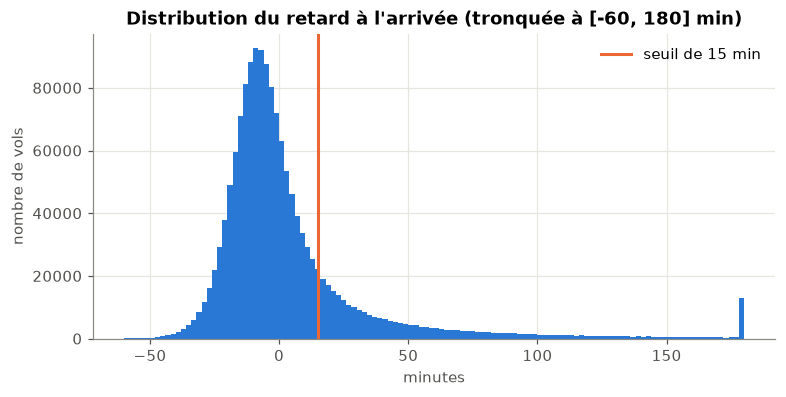

count    1500000.0
mean           4.4
std           39.1
min          -82.0
25%          -13.0
50%           -5.0
75%            8.0
max         1636.0


In [5]:
df = F.ajouter_variables_calendrier(df)
MOYENNE = df["RETARD"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(df["ARRIVAL_DELAY"].clip(-60, 180), bins=120, color=E.BLEU)
ax.axvline(F.SEUIL_RETARD, color=E.ORANGE, lw=2, label="seuil de 15 min")
ax.set(title="Distribution du retard à l'arrivée (tronquée à [-60, 180] min)", xlabel="minutes", ylabel="nombre de vols")
ax.legend(); plt.show()
print(df["ARRIVAL_DELAY"].describe().round(1).to_string())

**Interprétation :** la plupart des vols arrivent **en avance** (médiane de -5 minutes, car les compagnies gonflent les durées prévues). Seuls **17,9 %** dépassent 15 minutes de retard, avec une longue traîne jusqu'à plus de 24 heures. Les classes sont donc **déséquilibrées**, ce qui oriente le choix des métriques (section 6).

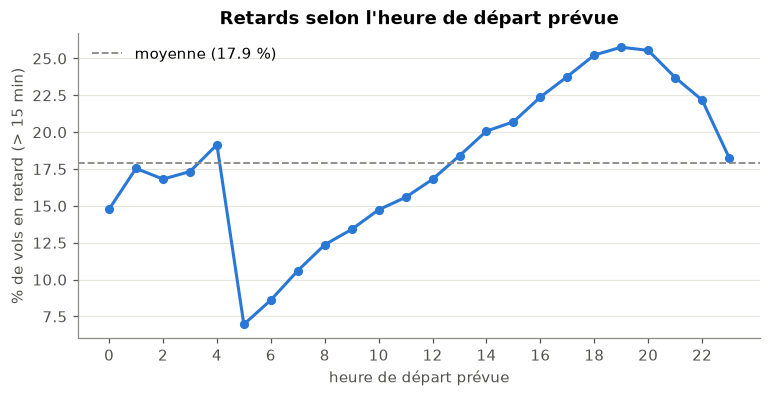

In [6]:
t = E.taux_retard(df, "HEURE_DEP")
fig, ax = plt.subplots(figsize=(8, 3.6))
E.graphique_taux(t["taux"], "Retards selon l'heure de départ prévue", "heure de départ prévue", MOYENNE, kind="line", ax=ax)
ax.set_xticks(range(0, 24, 2)); E.sauver(fig, "eda_heure"); plt.show()

**Interprétation :** c'est l'effet le plus net. Le taux de retard passe de **7 % pour les départs de 5 h** à **près de 26 % vers 19 h**. C'est l'effet « boule de neige » : un avion fait plusieurs rotations par jour, et chaque retard se répercute sur les vols suivants. Les vols de nuit (0 h à 4 h) sont rares (moins de 0,5 % des vols), donc leurs taux sont peu fiables.

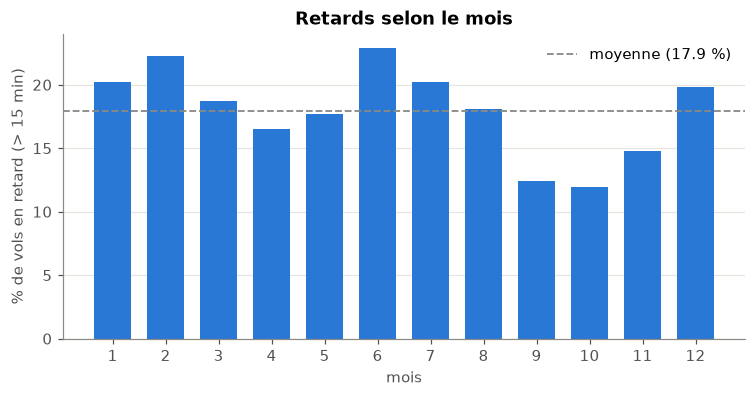

In [7]:
t = E.taux_retard(df, "MONTH")
fig, ax = plt.subplots(figsize=(8, 3.6))
E.graphique_taux(t["taux"], "Retards selon le mois", "mois", MOYENNE, ax=ax)
E.sauver(fig, "eda_mois"); plt.show()

**Interprétation :** les retards suivent la **saison**. Les pics sont en **juin** (22,9 %, orages d'été et forte affluence), en **février** (22,3 %, neige) et en décembre. **Septembre et octobre** sont les mois les plus calmes (environ 12 %). ⚠️ Conséquence pour la suite : les mois de test (septembre, novembre, décembre) ont en moyenne **moins de retards** que les mois d'entraînement. Il faudra s'en souvenir en lisant les scores, car la PR-AUC dépend de la proportion de retards.

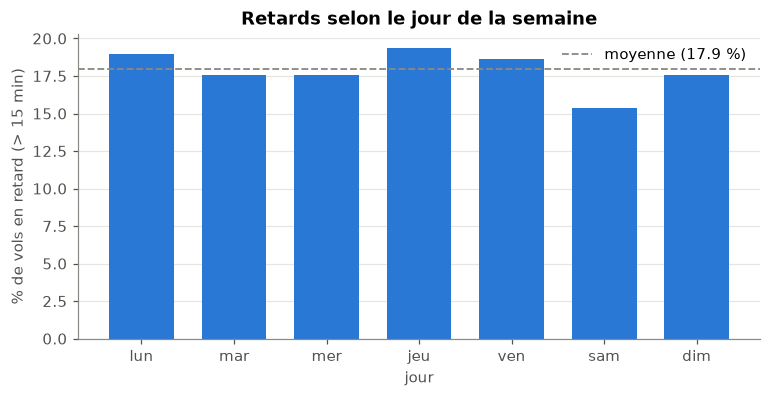

In [8]:
t = E.taux_retard(df, "DAY_OF_WEEK")
t.index = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
fig, ax = plt.subplots(figsize=(8, 3.6))
E.graphique_taux(t["taux"], "Retards selon le jour de la semaine", "jour", MOYENNE, ax=ax)
plt.show()

**Interprétation :** l'effet du jour de la semaine est **modéré**. Le **samedi** est nettement le plus calme (15,4 %, moins de vols d'affaires), alors que le **jeudi** et le **lundi** sont les plus chargés (environ 19 %).

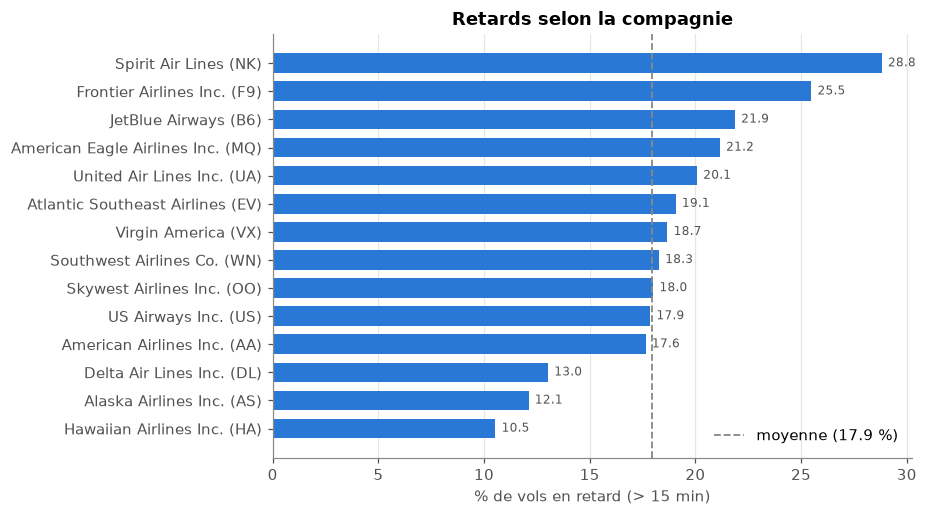

In [9]:
t = E.taux_retard(df, "AIRLINE")["taux"].sort_values()
t.index = [f"{airlines.get(c, c)} ({c})" for c in t.index]
fig, ax = plt.subplots(figsize=(7.5, 5))
E.graphique_taux(t, "Retards selon la compagnie", "", MOYENNE, kind="barh", ax=ax)
E.sauver(fig, "eda_compagnie"); plt.show()

**Interprétation :** l'écart entre compagnies va presque **du simple au triple**. Les compagnies à bas coût **Spirit (28,8 %)** et **Frontier (25,5 %)** sont les moins ponctuelles. Elles exploitent leurs avions de façon très intensive, donc avec peu de marge pour absorber un retard. **Hawaiian (10,5 %)**, **Alaska (12,1 %)** et **Delta (13,0 %)** sont les plus ponctuelles. La compagnie sera donc une variable importante.

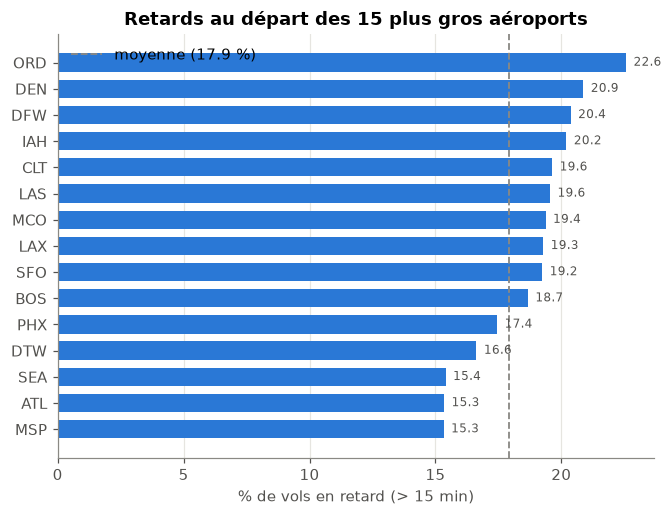

In [10]:
top = df["ORIGIN_AIRPORT"].value_counts().head(15).index
t = E.taux_retard(df[df["ORIGIN_AIRPORT"].isin(top)], "ORIGIN_AIRPORT")["taux"].sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
E.graphique_taux(t, "Retards au départ des 15 plus gros aéroports", "", MOYENNE, kind="barh", ax=ax)
plt.show()

**Interprétation :** **Chicago O'Hare (ORD, 22,6 %)** et **Denver (DEN, 20,9 %)** sont les plus touchés (hiver rigoureux, orages). **Atlanta (ATL)**, pourtant l'aéroport le plus fréquenté du monde, fait partie des meilleurs (15,3 %), avec Minneapolis (MSP) et Seattle (SEA). Le volume seul n'explique donc pas les retards : l'organisation de l'aéroport et le climat comptent aussi.

## 3. Feature engineering

Toutes les variables sont **connues au moment de la réservation** :

| Famille | Variables | Pourquoi |
|---|---|---|
| Calendrier | `MONTH`, `DAY_OF_WEEK`, `JOUR_ANNEE`, `JOURS_FERIE` (jours jusqu'au férié le plus proche) | saison, affluence des vacances |
| Horaires | `HEURE_DEP`, `HEURE_ARR` (heures prévues) | effet boule de neige au fil de la journée |
| Vol | `AIRLINE`, `ORIGIN_AIRPORT`, `DESTINATION_AIRPORT`, `DISTANCE`, `SCHEDULED_TIME` | compagnie, aéroports, type de vol |
| Trafic | `TRAFIC_HEURE` : départs **prévus** depuis l'aéroport dans la même heure | saturation (programme publié à l'avance) |
| **Historique** | `TAUX_HIST_ORIGINE`, `TAUX_HIST_DESTINATION`, `TAUX_HIST_COMPAGNIE`, `TAUX_HIST_LIGNE` | réputation passée de ponctualité |

### Mon amélioration : les taux de retard historiques

Pour chaque aéroport, compagnie et **ligne** (départ → arrivée), on calcule la part de vols en retard **dans le passé**. C'est un *encodage par la cible* (target encoding). Il est puissant, mais c'est aussi la source de fuite la plus classique, d'où trois précautions :

1. **Uniquement le passé.** Sur l'entraînement, le taux d'un vol du jour J n'utilise que les vols des jours **antérieurs à J**, jamais le vol lui-même ni les vols du même jour.
2. **Figé pour l'avenir.** Sur la validation et le test, le taux est **figé à la date de coupure**. Au moment de réserver un vol de décembre, on ne connaît pas encore les retards de novembre.
3. **Lissage bayésien** pour les petites catégories : `taux = (retards + m × taux_global) / (vols + m)`, avec `m = 50`. Une ligne vue 3 fois avec 2 retards ne vaut donc pas 67 %, mais reste proche de la moyenne. Une ligne vue 5 000 fois suit ses propres données.

La ligne apporte une information que les variables séparées n'ont pas : une ligne précise peut être chroniquement en retard, sans que ses deux aéroports le soient en moyenne.

In [11]:
SEP = F.separer_temps(df)
# Taux historiques : coupure au 1er août pour l'entraînement et la validation,
# figés au 1er septembre pour le test. Aéroports hors top 100 de l'entraînement → « AUTRE ».
jeu = F.construire_jeu_modele(df)
jeu.loc[SEP["entrainement"], F.NUM_HIST].describe().round(3)

,TAUX_HIST_ORIGINE,TAUX_HIST_DESTINATION,TAUX_HIST_COMPAGNIE,TAUX_HIST_LIGNE
count,871280.000,871280.000,871280.000,871280.000
mean,0.209,0.208,0.208,0.208
std,0.057,0.051,0.058,0.058
min,0.078,0.083,0.073,0.060
25%,0.172,0.174,0.179,0.167
50%,0.199,0.202,0.200,0.203
75%,0.235,0.228,0.222,0.243
max,0.586,0.536,0.569,0.496


### Vérification explicite : les taux historiques ne fuient pas

On fait un **test de perturbation**. On remplace au hasard toutes les cibles à partir du 1er juin, puis on recalcule les taux historiques. Si la variable ne regarde que le passé, **aucune** valeur avant le 1er juin ne doit changer, et les valeurs du test (figées au 1er septembre) non plus. Le même test est automatisé dans `tests/test_features.py`.

In [12]:
rng = np.random.default_rng(SEED)
perturbe = df.copy()
futur = perturbe["DATE"] >= "2015-06-01"
perturbe.loc[futur, "RETARD"] = rng.integers(0, 2, futur.sum()).astype("int8")
dt_perturbe = F.ajouter_taux_historiques(perturbe, F.DEBUT_TEST)

avant_juin = ~futur
identiques = np.allclose(dt_perturbe.loc[avant_juin, F.NUM_HIST], F.ajouter_taux_historiques(df, F.DEBUT_TEST).loc[avant_juin, F.NUM_HIST], equal_nan=True)
print("Valeurs avant juin inchangées :", identiques)

# Les valeurs du test ne dépendent que de janvier-août : perturber les cibles du test ne change rien
perturbe_test = df.copy()
perturbe_test.loc[SEP["test"], "RETARD"] = 1 - perturbe_test.loc[SEP["test"], "RETARD"]
inchange_test = np.allclose(F.ajouter_taux_historiques(perturbe_test, F.DEBUT_TEST).loc[SEP["test"], F.NUM_HIST],
                            F.ajouter_taux_historiques(df, F.DEBUT_TEST).loc[SEP["test"], F.NUM_HIST])
print("Valeurs du test inchangées quand on inverse les cibles du test :", inchange_test)
assert identiques and inchange_test
del perturbe, perturbe_test, dt_perturbe

Valeurs avant juin inchangées : True


Valeurs du test inchangées quand on inverse les cibles du test : True


## 4. Séparation temporelle

On ne mélange **jamais** les vols au hasard. Une séparation aléatoire mettrait des vols du 14 juillet à la fois dans l'entraînement et dans le test : le modèle « connaîtrait » déjà la météo et les incidents de ce jour-là, et le score serait trop optimiste. En pratique, on entraîne sur le **passé** pour prédire le **futur** :

| Jeu | Période | Rôle |
|---|---|---|
| Entraînement | janvier → juillet | apprendre les paramètres |
| Validation | août (fin de la période d'entraînement) | arrêt anticipé de LightGBM, **choix du seuil** |
| Test | septembre, novembre, décembre | **évaluation finale** |

Octobre n'est utilisé ni pour l'entraînement ni pour le test.

> 📝 **Note de méthode (transparence).** Une première version réentraînait le modèle final sur janvier-août, puis lui appliquait le seuil choisi en validation pour le modèle janvier-juillet. Ce seuil n'avait donc pas été choisi pour le modèle évalué : les probabilités du modèle réentraîné étaient décalées, et le rappel de LightGBM sur le test s'effondrait (14 %). Cette version a été corrigée après avoir vu le test une fois. **Le modèle évalué est désormais exactement celui dont le seuil a été choisi sur la validation.** Aucun autre choix (variables, paramètres) n'a été modifié au vu du test.

In [13]:
CAT, NUM = F.CAT, F.NUM_BASE + F.NUM_HIST
VARIABLES = CAT + NUM

X_tr, y_tr = jeu.loc[SEP["entrainement"], VARIABLES], jeu.loc[SEP["entrainement"], "RETARD"]
X_val, y_val = jeu.loc[SEP["validation"], VARIABLES], jeu.loc[SEP["validation"], "RETARD"]
X_test, y_test = jeu.loc[SEP["test"], VARIABLES], jeu.loc[SEP["test"], "RETARD"]

assert jeu.loc[SEP["entrainement"], "DATE"].max() < jeu.loc[SEP["validation"], "DATE"].min()
assert jeu.loc[SEP["validation"], "DATE"].max() < jeu.loc[SEP["test"], "DATE"].min()
assert not set(VARIABLES) & set(F.COLONNES_INTERDITES), "variable interdite utilisée"

for nom, y in [("Entraînement (jan-juil)", y_tr), ("Validation (août)", y_val), ("Test (sept, nov, déc)", y_test)]:
    print(f"{nom:<30} {len(y):>9,} vols | {y.mean():.1%} de retards")

Entraînement (jan-juil)          874,749 vols | 19.7% de retards
Validation (août)                132,338 vols | 18.1% de retards
Test (sept, nov, déc)            366,264 vols | 15.7% de retards


## 5. Modèles

Les classes sont **déséquilibrées** (environ 1 vol sur 5 en retard). L'exactitude (*accuracy*) est donc trompeuse : un modèle qui répond toujours « à l'heure » aurait déjà plus de 80 %. On utilise plutôt :
- **ROC-AUC** : probabilité qu'un vol en retard tiré au hasard reçoive un score plus élevé qu'un vol à l'heure tiré au hasard (0,5 = hasard, 1 = parfait). Elle ne dépend pas de la proportion de retards.
- **PR-AUC** (précision moyenne) : centrée sur la classe rare. Le hasard vaut la **part de retards** du jeu évalué. C'est la métrique la plus honnête ici, mais elle n'est comparable qu'à proportion de retards égale.
- **Précision / rappel / F1** au seuil choisi sur la **validation**. La précision répond à « quand le modèle annonce un retard, a-t-il raison ? », le rappel à « quelle part des retards a-t-il repérée ? ».

In [14]:
resultats_val, resultats_test, probas_test, seuils = {}, {}, {}, {}

def evaluer(nom, proba_val, proba_test):
    """Choisit le seuil sur la validation, puis mesure validation et test avec ce même seuil."""
    seuils[nom] = E.choisir_seuil(y_val, proba_val)
    resultats_val[nom] = E.metriques(y_val, proba_val, seuils[nom])
    resultats_test[nom] = E.metriques(y_test, proba_test, seuils[nom])
    probas_test[nom] = np.asarray(proba_test)
    r = resultats_test[nom]
    print(f"{nom:<28} TEST  ROC-AUC = {r['ROC-AUC']:.3f} | PR-AUC = {r['PR-AUC']:.3f} | F1 = {r['F1']:.3f}  (seuil {seuils[nom]:.3f})")

### 5.1 Références naïves

- **Constante** : la même probabilité (taux de retard de l'entraînement) pour tous les vols. ROC-AUC = 0,5 par construction ; au seuil choisi, elle revient à « tout prédire en retard » (rappel 100 %).
- **Taux historique de la compagnie** : une règle métier simple, du type « Spirit est souvent en retard ». Un modèle de machine learning doit faire **nettement mieux** que cette règle pour être utile.

In [15]:
evaluer("Référence : constante", np.full(len(y_val), y_tr.mean()), np.full(len(y_test), y_tr.mean()))
evaluer("Référence : compagnie", X_val["TAUX_HIST_COMPAGNIE"], X_test["TAUX_HIST_COMPAGNIE"])

Référence : constante        TEST  ROC-AUC = 0.500 | PR-AUC = 0.157 | F1 = 0.271  (seuil 0.197)
Référence : compagnie        TEST  ROC-AUC = 0.538 | PR-AUC = 0.172 | F1 = 0.271  (seuil 0.187)


**Interprétation :** la règle « certaines compagnies sont souvent en retard » ne fait guère mieux que le hasard (ROC-AUC 0,538). La compagnie seule distingue mal les vols, car les écarts *à l'intérieur* d'une compagnie (heure, aéroport, saison) sont bien plus grands que les écarts *entre* compagnies.

### 5.2 Régression logistique

C'est un modèle linéaire, simple et interprétable. Il ne capte pas seul les effets non linéaires, par exemple le pic de retards vers 19 h. On encode donc l'**heure** et le **jour de la semaine** en catégories (one-hot), comme les compagnies et les aéroports. Les variables numériques sont normalisées, et les rares valeurs manquantes (premier jour de l'année, sans historique) sont imputées par la médiane.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

CAT_LR = CAT + ["HEURE_DEP", "DAY_OF_WEEK"]
NUM_LR = [c for c in NUM if c not in CAT_LR]

def regression_logistique():
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CAT_LR),
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM_LR)])
    return make_pipeline(prep, LogisticRegression(max_iter=500, C=1.0))

t0 = time.time()
logreg = regression_logistique().fit(X_tr, y_tr)
print(f"Entraînement : {time.time() - t0:.0f} s")
evaluer("Régression logistique", logreg.predict_proba(X_val)[:, 1], logreg.predict_proba(X_test)[:, 1])

Entraînement : 4 s


Régression logistique        TEST  ROC-AUC = 0.622 | PR-AUC = 0.225 | F1 = 0.308  (seuil 0.215)


### 5.3 LightGBM (gradient boosting d'arbres)

**Pourquoi LightGBM plutôt que XGBoost sur un Mac M2 avec 8 Go ?** Les deux sont d'excellents modèles de gradient boosting sur données tabulaires. LightGBM a ici trois avantages :
- il gère **nativement** les variables catégorielles (compagnies, aéroports), sans encodage one-hot ;
- il construit ses arbres **feuille par feuille sur des histogrammes**, ce qui le rend rapide et économe en mémoire sur processeur ;
- il tourne sur le processeur ARM du M2 sans GPU (il faut seulement `brew install libomp`).

**Arrêt anticipé (early stopping) :** on ajoute des arbres tant que la PR-AUC de validation (août) progresse, et on s'arrête après 100 arbres sans amélioration. Cela évite le sur-apprentissage.

In [17]:
import lightgbm as lgb

PARAMS = dict(learning_rate=0.05, num_leaves=63, min_child_samples=200, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, random_state=SEED, verbose=-1, n_jobs=-1)

def entrainer_lgbm(variables):
    modele = lgb.LGBMClassifier(n_estimators=3000, **PARAMS)
    modele.fit(X_tr[variables], y_tr, eval_X=(X_val[variables],), eval_y=(y_val,),
               eval_metric="average_precision", callbacks=[lgb.early_stopping(100, verbose=False)])
    return modele

t0 = time.time()
lgbm = entrainer_lgbm(VARIABLES)
print(f"Arrêt anticipé : {lgbm.best_iteration_} arbres ({time.time() - t0:.0f} s)")
proba_lgbm = lgbm.predict_proba(X_test)[:, 1]
evaluer("LightGBM", lgbm.predict_proba(X_val)[:, 1], proba_lgbm)

Arrêt anticipé : 54 arbres (4 s)


LightGBM                     TEST  ROC-AUC = 0.623 | PR-AUC = 0.223 | F1 = 0.311  (seuil 0.195)


**Contrôle anti-fuite.** Un score trop beau (ROC-AUC > 0,85) serait suspect : sans la météo du jour ni le retard de l'avion précédent, il est impossible de prédire aussi bien. On compare aussi l'entraînement et le test. Un écart énorme signalerait du sur-apprentissage ; un score de test supérieur à celui de l'entraînement signalerait une fuite.

In [18]:
from sklearn.metrics import roc_auc_score
auc_train = roc_auc_score(y_tr, lgbm.predict_proba(X_tr)[:, 1])
auc_test = resultats_test["LightGBM"]["ROC-AUC"]
print(f"ROC-AUC entraînement : {auc_train:.3f} | test : {auc_test:.3f}")
assert auc_test < 0.85, "Score suspect : chercher une fuite de données avant de continuer"

ROC-AUC entraînement : 0.720 | test : 0.623


**Interprétation :** aucun signe de fuite. Le score de test (0,62) est **inférieur** à celui de l'entraînement (0,72) et très loin du seuil d'alerte de 0,85. L'écart vient surtout du **glissement dans le temps** : l'arrêt anticipé intervient dès 54 arbres, car au-delà le modèle apprend des particularités de janvier-juillet (épisodes météo, incidents) qui ne se répètent pas en août.

### 5.4 Les taux historiques apportent-ils quelque chose ?

On réentraîne exactement le même LightGBM **sans** les 4 variables historiques (étude d'ablation).

In [19]:
VAR_SANS_HIST = CAT + F.NUM_BASE
p_test_sh = entrainer_lgbm(VAR_SANS_HIST).predict_proba(X_test[VAR_SANS_HIST])[:, 1]

# Même chose pour la régression logistique, pour qui ces variables résument des milliers de lignes
cat_sh = [c for c in CAT_LR]; num_sh = [c for c in F.NUM_BASE if c not in CAT_LR]
lr_sh = make_pipeline(ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), cat_sh),
                                         ("num", StandardScaler(), num_sh)]), LogisticRegression(max_iter=500))
p_test_lr_sh = lr_sh.fit(X_tr, y_tr).predict_proba(X_test)[:, 1]

ablation = pd.DataFrame({
    "avec taux historiques": [resultats_test["Régression logistique"]["ROC-AUC"], resultats_test["Régression logistique"]["PR-AUC"],
                              resultats_test["LightGBM"]["ROC-AUC"], resultats_test["LightGBM"]["PR-AUC"]],
    "sans taux historiques": [roc_auc_score(y_test, p_test_lr_sh), E.metriques(y_test, p_test_lr_sh, 0.5)["PR-AUC"],
                              roc_auc_score(y_test, p_test_sh), E.metriques(y_test, p_test_sh, 0.5)["PR-AUC"]],
}, index=pd.MultiIndex.from_product([["Régression logistique", "LightGBM"], ["ROC-AUC", "PR-AUC"]]))
ablation["gain"] = ablation["avec taux historiques"] - ablation["sans taux historiques"]
ablation.round(4)

avec taux historiques  sans taux historiques  \
Régression logistique ROC-AUC                 0.6224                 0.6142   
                      PR-AUC                  0.2247                 0.2167   
LightGBM              ROC-AUC                 0.6233                 0.6240   
                      PR-AUC                  0.2226                 0.2239   

                                 gain  
Régression logistique ROC-AUC  0.0083  
                      PR-AUC   0.0080  
LightGBM              ROC-AUC -0.0007  
                      PR-AUC  -0.0013

**Interprétation (résultat honnête sur mon amélioration) :**
- Pour la **régression logistique**, les taux historiques apportent un gain modeste mais réel, d'environ **+0,008** en ROC-AUC et en PR-AUC. Ils résument en un seul nombre l'effet de milliers de lignes qu'un modèle linéaire ne peut pas apprendre une par une.
- Pour **LightGBM**, ils n'apportent **rien** (l'écart est de l'ordre du bruit). Le modèle apprend déjà directement l'effet de chaque compagnie et de chaque aéroport à partir des variables catégorielles. De plus, sur le test, les taux sont figés au 1er septembre et vieillissent au fil des mois.
- Leçon : un encodage par la cible est surtout utile quand le modèle ne peut pas exploiter lui-même les catégories (modèles linéaires, catégories très nombreuses). Il n'est pas magique avec le gradient boosting.

## 6. Évaluation

In [20]:
tableau = pd.DataFrame(resultats_test).T
tableau.insert(2, "PR-AUC du hasard", y_test.mean())
print("Résultats sur le TEST (septembre, novembre, décembre) — seuils choisis sur la validation")
tableau.round(3)

Résultats sur le TEST (septembre, novembre, décembre) — seuils choisis sur la validation


,ROC-AUC,PR-AUC,PR-AUC du hasard,Précision,Rappel,F1,Seuil
Référence : constante,0.500,0.157,0.157,0.157,1.000,0.271,0.197
Référence : compagnie,0.538,0.172,0.157,0.166,0.743,0.271,0.187
Régression logistique,0.622,0.225,0.157,0.197,0.712,0.308,0.215
LightGBM,0.623,0.223,0.157,0.205,0.645,0.311,0.195


In [21]:
print("Résultats sur la VALIDATION (août)")
pd.DataFrame(resultats_val).T.round(3)

Résultats sur la VALIDATION (août)


,ROC-AUC,PR-AUC,Précision,Rappel,F1,Seuil
Référence : constante,0.500,0.181,0.181,1.000,0.306,0.197
Référence : compagnie,0.540,0.203,0.190,0.834,0.310,0.187
Régression logistique,0.646,0.271,0.253,0.618,0.359,0.215
LightGBM,0.658,0.284,0.255,0.652,0.367,0.195


**Interprétation :**
- **Les deux modèles battent nettement les références.** Sur le test, la PR-AUC passe de 0,157 (hasard) et 0,172 (règle de la compagnie) à environ **0,22**, soit **+42 %** par rapport au hasard. La ROC-AUC passe de 0,54 à **0,62**.
- **LightGBM et la régression logistique sont à égalité sur le test** (0,623 contre 0,622 en ROC-AUC). LightGBM est un peu meilleur sur la validation d'août (0,658 contre 0,646), mais cet avantage disparaît quand on prédit plus loin dans le futur. Les interactions complexes qu'il apprend vieillissent plus vite que les effets simples de la régression logistique.
- **Les scores baissent entre la validation et le test** (ROC-AUC de 0,66 à 0,62). C'est attendu : le test est plus loin dans le temps (1 à 4 mois après la fin de l'entraînement) et contient des mois jamais vus.
- Ces scores sont **modestes, et c'est normal** : sans la météo du jour ni le retard de l'avion précédent, l'essentiel du retard est imprévisible au moment de la réservation. Un modèle à 0,95 aurait été suspect.

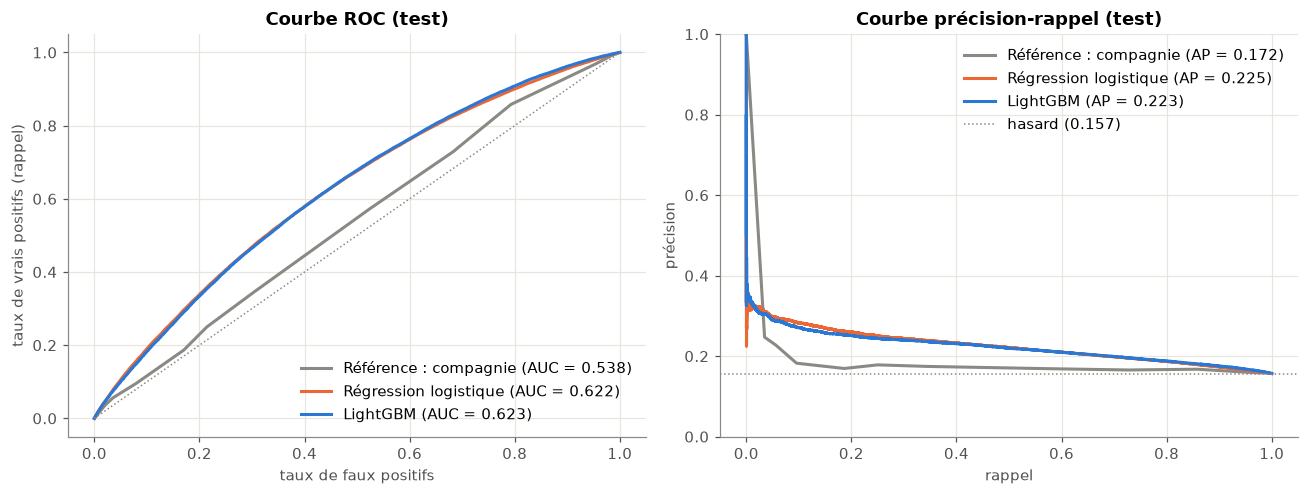

In [22]:
fig = E.courbes_roc_pr(y_test, {k: v for k, v in probas_test.items() if k != "Référence : constante"}, " (test)")
E.sauver(fig, "courbes_roc_pr"); plt.show()

Seuil retenu (validation) : 0.195

              precision    recall  f1-score   support

   à l'heure      0.890     0.535     0.669    308826
   en retard      0.205     0.645     0.311     57438

    accuracy                          0.552    366264
   macro avg      0.548     0.590     0.490    366264
weighted avg      0.783     0.552     0.613    366264



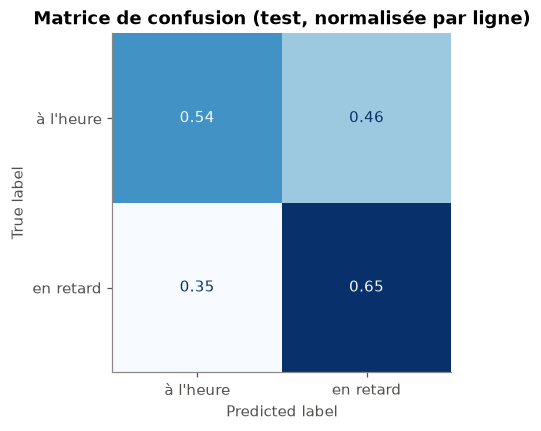

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
SEUIL = seuils["LightGBM"]
pred = (proba_lgbm >= SEUIL).astype(int)
print(f"Seuil retenu (validation) : {SEUIL:.3f}\n")
print(classification_report(y_test, pred, target_names=["à l'heure", "en retard"], digits=3))
fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred, normalize="true"),
                       display_labels=["à l'heure", "en retard"]).plot(cmap="Blues", values_format=".2f", ax=ax, colorbar=False)
ax.grid(False); ax.set_title("Matrice de confusion (test, normalisée par ligne)"); plt.show()

**Interprétation du seuil (0,195) :** avec ce seuil, le modèle repère **65 % des vols en retard** (rappel). En contrepartie, seule **1 alerte sur 5 est justifiée** (précision 20,5 %), et 46 % des vols à l'heure sont signalés à tort. L'exactitude tombe à 55 %, bien en dessous des 84 % d'un modèle qui dirait toujours « à l'heure ». Cela montre que l'exactitude n'est pas la bonne métrique ici. Le seuil maximisant le F1 est **un choix métier**. Pour afficher un badge « risque élevé » à des clients, on préférerait un seuil plus haut : moins d'alertes, mais plus fiables.

In [24]:
# Résultats par mois de test : la proportion de retards varie beaucoup d'un mois à l'autre
par_mois = pd.DataFrame({m: E.metriques(y_test[X_test["MONTH"] == m], proba_lgbm[X_test["MONTH"] == m], SEUIL)
                         for m in F.MOIS_TEST}).T
par_mois.insert(0, "taux de retard", [y_test[X_test["MONTH"] == m].mean() for m in F.MOIS_TEST])
par_mois.insert(1, "proba moyenne prédite", [proba_lgbm[X_test["MONTH"] == m].mean() for m in F.MOIS_TEST])
par_mois.round(3)

,taux de retard,proba moyenne prédite,ROC-AUC,PR-AUC,Précision,Rappel,F1,Seuil
9,0.124,0.212,0.633,0.177,0.168,0.666,0.268,0.195
11,0.148,0.210,0.623,0.210,0.194,0.645,0.298,0.195
12,0.198,0.213,0.619,0.278,0.253,0.632,0.361,0.195


**Interprétation :** le modèle **classe** les vols de façon régulière d'un mois à l'autre (ROC-AUC entre 0,62 et 0,63), mais sa **probabilité moyenne reste figée autour de 21 %**. Or le taux réel varie de 12 % en septembre à 20 % en décembre. Le modèle ne peut pas connaître la saisonnalité de mois qu'il n'a jamais vus : pour les arbres, un vol de décembre ressemble à un vol de fin août. C'est une limite directe du fait de n'avoir qu'**une seule année** de données.

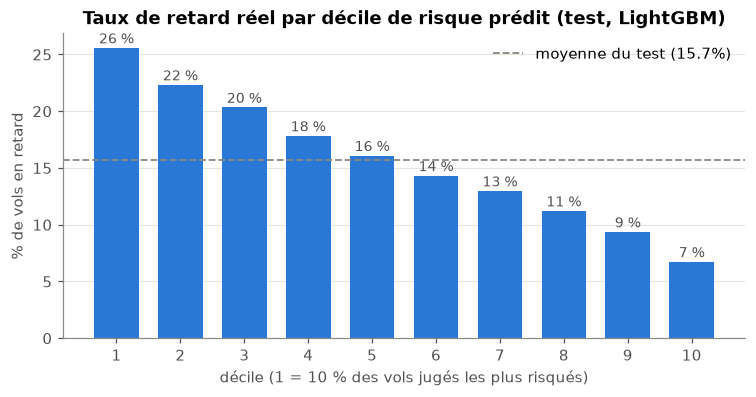

Décile le plus risqué : 25.6 % de retards, soit 3.8 fois le décile le moins risqué (6.7 %)


In [25]:
# Lecture « métier » : on classe les vols du test du plus risqué au moins risqué, en 10 groupes égaux
deciles = pd.qcut(pd.Series(proba_lgbm).rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = pd.DataFrame({"y": y_test.to_numpy(), "decile": deciles}).groupby("decile", observed=True)["y"].mean().mul(100)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(lift.index.astype(str), lift.values, color=E.BLEU, width=0.7)
ax.axhline(y_test.mean() * 100, color=E.GRIS, ls="--", lw=1.2, label=f"moyenne du test ({y_test.mean():.1%})")
for i, v in enumerate(lift.values):
    ax.text(i, v + 0.4, f"{v:.0f} %", ha="center", fontsize=9, color=E.ENCRE)
ax.set(title="Taux de retard réel par décile de risque prédit (test, LightGBM)",
       xlabel="décile (1 = 10 % des vols jugés les plus risqués)", ylabel="% de vols en retard")
ax.grid(axis="x", visible=False); ax.legend(); E.sauver(fig, "deciles_risque"); plt.show()
print(f"Décile le plus risqué : {lift.iloc[0]:.1f} % de retards, soit {lift.iloc[0] / lift.iloc[-1]:.1f} fois le décile le moins risqué ({lift.iloc[-1]:.1f} %)")

**Interprétation :** c'est la lecture la plus parlante pour un métier. Les 10 % de vols que le modèle juge les plus risqués ont **25,6 %** de retards, soit **3,8 fois plus** que les 10 % jugés les plus sûrs (6,7 %). Le modèle ne prédit pas chaque retard, mais il **trie** efficacement les vols par niveau de risque. C'est exactement ce dont on a besoin pour afficher un indicateur de fiabilité ou conseiller une correspondance plus longue.

## 7. Interprétation : quelles variables comptent ?

### 7.1 Importance des variables (gain LightGBM)

Le **gain** mesure de combien chaque variable a amélioré la qualité des arbres, en cumulé sur toutes les divisions qui l'utilisent. C'est rapide à obtenir, mais cela ne dit ni dans quel **sens** joue la variable, ni ce qui se passe pour un vol donné.

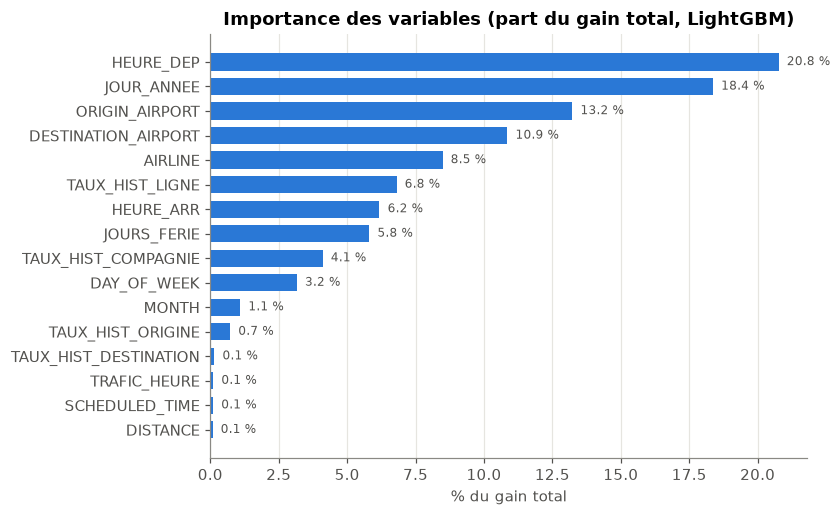

In [26]:
imp = pd.Series(lgbm.booster_.feature_importance("gain"), index=lgbm.booster_.feature_name())
imp = (100 * imp / imp.sum()).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp.index, imp.values, color=E.BLEU, height=0.7)
for i, v in enumerate(imp.values):
    ax.text(v + 0.3, i, f"{v:.1f} %", va="center", fontsize=8, color=E.ENCRE)
ax.set(title="Importance des variables (part du gain total, LightGBM)", xlabel="% du gain total")
ax.grid(axis="y", visible=False); plt.show()

### 7.2 SHAP

**SHAP** (SHapley Additive exPlanations) répartit la prédiction de chaque vol entre les variables, comme on partagerait équitablement un gain entre les joueurs d'une équipe (valeurs de Shapley, issues de la théorie des jeux). Pour chaque vol :

`prédiction (en log-odds) = valeur moyenne + somme des contributions SHAP de chaque variable`

Une contribution positive pousse vers « retard », une contribution négative vers « à l'heure ». On calcule SHAP sur un **échantillon de 5 000 vols du test**, ce qui suffit pour des graphiques stables et reste rapide.

In [27]:
import shap

X_shap = X_test.sample(5000, random_state=SEED)
explication = shap.TreeExplainer(lgbm)(X_shap)
shap_abs = pd.Series(np.abs(explication.values).mean(axis=0), index=VARIABLES).sort_values(ascending=False)
print("Contribution absolue moyenne (log-odds) :")
print(shap_abs.round(3).to_string())

Contribution absolue moyenne (log-odds) :
HEURE_DEP                0.294
HEURE_ARR                0.117
AIRLINE                  0.113
TAUX_HIST_LIGNE          0.095
JOUR_ANNEE               0.083
ORIGIN_AIRPORT           0.079
DESTINATION_AIRPORT      0.074
DAY_OF_WEEK              0.038
JOURS_FERIE              0.033
TAUX_HIST_COMPAGNIE      0.023
MONTH                    0.007
TAUX_HIST_ORIGINE        0.003
TRAFIC_HEURE             0.002
DISTANCE                 0.002
SCHEDULED_TIME           0.001
TAUX_HIST_DESTINATION    0.001


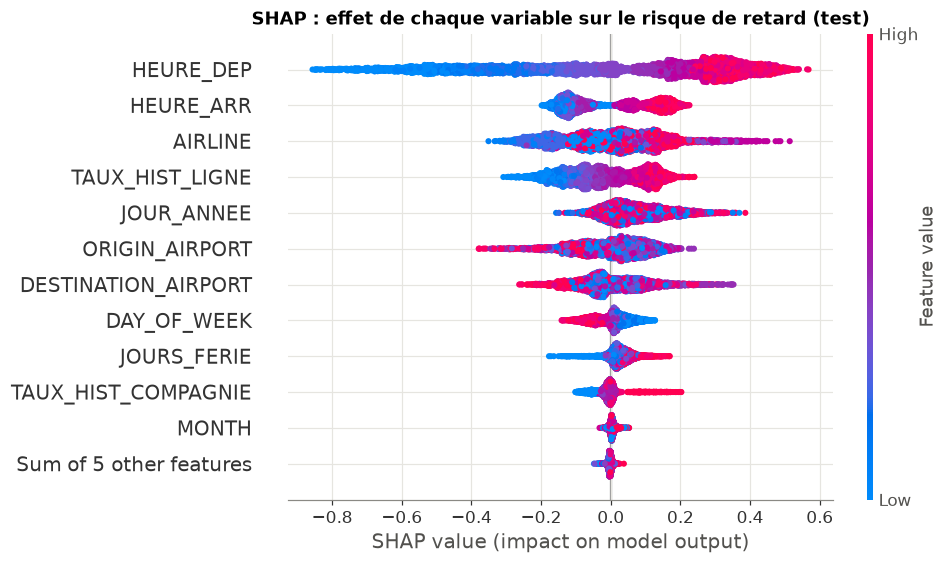

In [28]:
# Beeswarm : chaque point est un vol ; couleur = valeur de la variable (rouge = élevée)
explication_affichage = shap.Explanation(
    values=explication.values, base_values=explication.base_values,
    data=X_shap.apply(lambda c: c.cat.codes if c.dtype.name == "category" else c).to_numpy(dtype=float),
    feature_names=VARIABLES)
shap.plots.beeswarm(explication_affichage, max_display=12, show=False)
fig = plt.gcf(); fig.set_size_inches(8, 5.5)
plt.title("SHAP : effet de chaque variable sur le risque de retard (test)")
E.sauver(fig, "shap_beeswarm"); plt.show()

*Lecture :* pour les variables numériques, rouge = valeur élevée et bleu = valeur faible. Pour les catégories (compagnie, aéroports), la couleur n'est qu'un numéro de code sans ordre : on regarde seulement l'étalement horizontal, et le graphique par compagnie ci-dessous donne le détail.

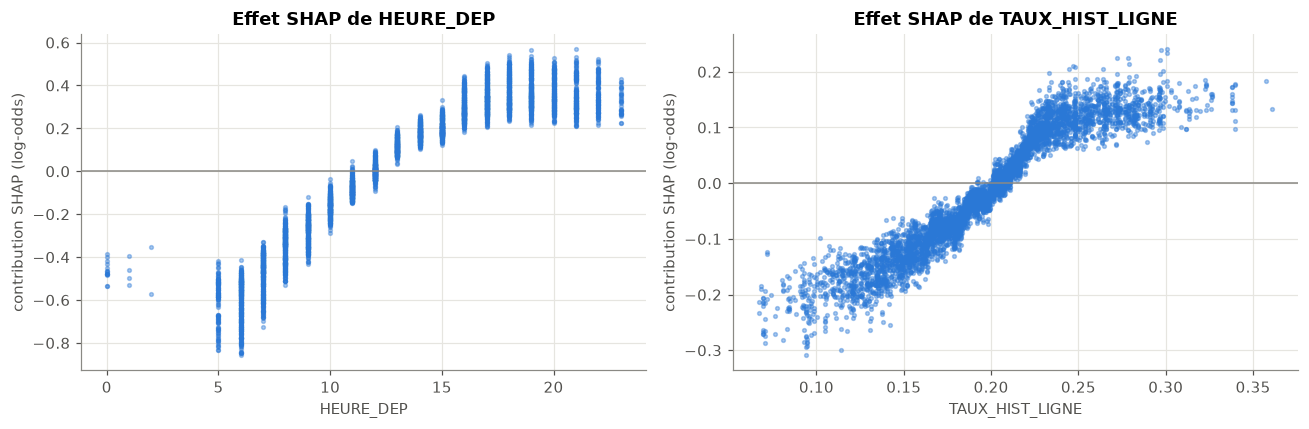

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, var in zip(axes, ["HEURE_DEP", "TAUX_HIST_LIGNE"]):
    ax.scatter(X_shap[var], explication.values[:, VARIABLES.index(var)], s=6, alpha=0.4, color=E.BLEU)
    ax.axhline(0, color=E.GRIS, lw=1)
    ax.set(title=f"Effet SHAP de {var}", xlabel=var, ylabel="contribution SHAP (log-odds)")
plt.tight_layout(); plt.show()

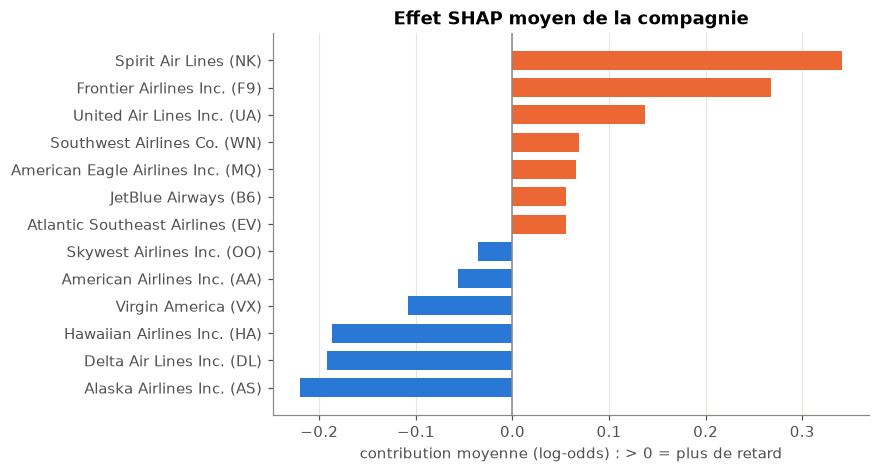

In [30]:
# Contribution SHAP moyenne par compagnie (variable catégorielle)
cie = pd.Series(explication.values[:, VARIABLES.index("AIRLINE")], index=X_shap["AIRLINE"].astype(str))
cie = cie.groupby(level=0).mean().sort_values()
cie.index = [f"{airlines.get(c, c)} ({c})" for c in cie.index]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(cie.index, cie.values, color=[E.ORANGE if v > 0 else E.BLEU for v in cie.values], height=0.7)
ax.axvline(0, color=E.GRIS, lw=1)
ax.set(title="Effet SHAP moyen de la compagnie", xlabel="contribution moyenne (log-odds) : > 0 = plus de retard")
ax.grid(axis="y", visible=False); plt.show()

**À quoi ressemble l'explication d'un vol ?** Voici le détail SHAP du vol de l'échantillon jugé le plus risqué :

{'AIRLINE': 'WN', 'ORIGIN_AIRPORT': 'LAS', 'DESTINATION_AIRPORT': 'LAX', 'MONTH': 12, 'HEURE_DEP': 18, 'JOURS_FERIE': 10}
Probabilité prédite : 56%


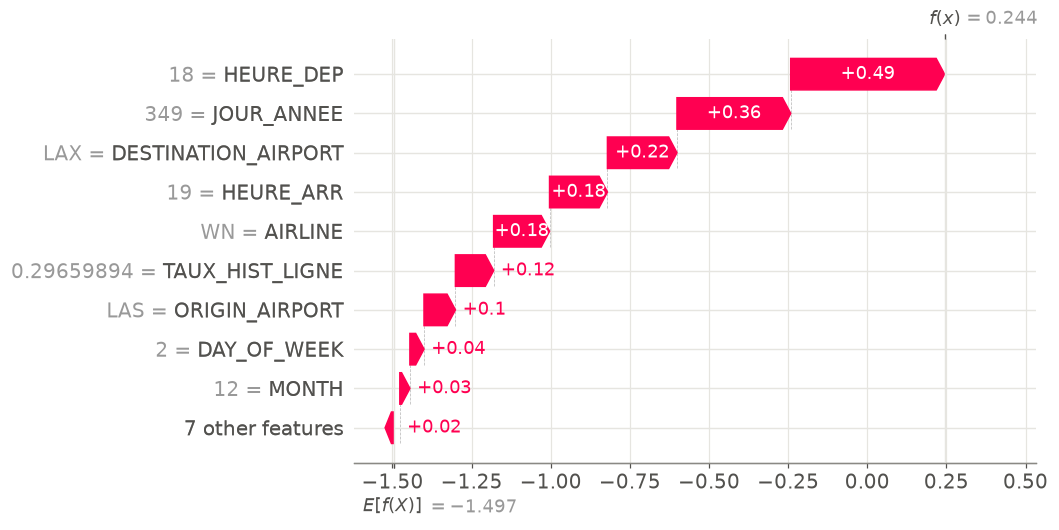

In [31]:
i = int(np.argmax(explication.values.sum(axis=1)))
print(X_shap.iloc[i][["AIRLINE", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT", "MONTH", "HEURE_DEP", "JOURS_FERIE"]].to_dict())
print(f"Probabilité prédite : {lgbm.predict_proba(X_shap.iloc[[i]])[0, 1]:.0%}")
explication_vol = shap.Explanation(values=explication.values[i], base_values=explication.base_values[i],
                                   data=X_shap.iloc[i].astype(str).to_numpy(), feature_names=VARIABLES)
shap.plots.waterfall(explication_vol, max_display=10, show=False)
plt.gcf().set_size_inches(8, 5); plt.show()

### Ce que disent les résultats, en français simple

- **L'heure de départ est de loin le premier facteur.** Sa contribution moyenne est presque trois fois celle de la variable suivante. Un vol à 6 h part avec un avion « frais » ; un vol à 19 h hérite de tous les petits retards accumulés dans la journée. Le modèle a retrouvé seul l'effet boule de neige vu dans l'analyse exploratoire.
- **Viennent ensuite la compagnie et la ligne.** Voler avec Spirit, Frontier ou United augmente le risque ; Delta, Alaska ou Hawaiian le réduisent. Le **taux historique de la ligne** (mon amélioration) est la 4e variable selon SHAP. L'ablation de la section 5.4 montre pourtant qu'il n'améliore pas le score de LightGBM : il **remplace** l'information des aéroports sans en ajouter de nouvelle. Les deux résultats sont compatibles : SHAP mesure *ce que le modèle utilise*, l'ablation mesure *ce qui est indispensable*.
- **Le calendrier compte moins que prévu.** Les jours proches d'un férié et le jour de la semaine ont un effet modéré. Le mois n'a presque aucun effet, car le modèle n'a jamais vu septembre ni décembre et ne peut donc pas apprendre leur saisonnalité.
- **La distance, la durée prévue et le trafic de l'heure ne servent presque à rien.** Leur effet est déjà capté par l'aéroport et l'heure de départ (un aéroport chargé est un grand hub, et ses heures de pointe sont aussi celles des retards).
- **L'exemple du vol le plus risqué** (Southwest, Las Vegas → Los Angeles, 15 décembre à 18 h, 56 % de risque). Le graphique part du score moyen (-1,50 en log-odds, environ 18 %) et chaque variable ajoute sa contribution. Le départ à 18 h ajoute +0,49, l'arrivée à Los Angeles +0,22, la compagnie Southwest +0,18 et la ligne LAS → LAX, historiquement en retard dans 30 % des cas, +0,12. ⚠️ Le **jour de l'année (349)** ajoute +0,36. Ce n'est **pas** un « effet fêtes » appris : le modèle n'a jamais vu décembre, donc il traite ce jour comme les derniers jours qu'il connaît. C'est un bon exemple de l'utilité de SHAP, qui rend visibles les extrapolations douteuses d'un modèle.

## 8. Analyse des erreurs : sur quels vols le modèle se trompe-t-il ?

On regarde le modèle au seuil choisi (0,195) segment par segment. Deux types d'erreurs :
- **retards manqués** (faux négatifs) : le vol était en retard, le modèle a dit « à l'heure » ;
- **fausses alertes** (faux positifs) : le vol était à l'heure, le modèle a dit « retard ».

La ROC-AUC par segment indique si le modèle sait **trier** les vols *à l'intérieur* du segment.

In [32]:
analyse = jeu.loc[SEP["test"]].copy()
analyse["TRANCHE_HORAIRE"] = pd.cut(analyse["HEURE_DEP"], [-1, 5, 11, 16, 20, 23],
                                    labels=["nuit (0-5h)", "matin (6-11h)", "après-midi (12-16h)", "soirée (17-20h)", "fin de soirée (21-23h)"])
analyse["DISTANCE_CLASSE"] = pd.cut(analyse["DISTANCE"], [0, 500, 1000, 2000, 5000],
                                    labels=["< 500 mi", "500-1000 mi", "1000-2000 mi", "> 2000 mi"])
erreurs = lambda col, **kw: E.erreurs_par_segment(analyse, y_test, proba_lgbm, SEUIL, col, **kw)
erreurs("TRANCHE_HORAIRE")

,vols,taux_retard_%,proba_moyenne_%,erreurs_%,retards_manqués_%,fausses_alertes_%,ROC-AUC
seg,,,,,,,
nuit (0-5h),9439.0,7.903,9.966,9.196,94.102,1.910,0.619
matin (6-11h),142480.0,11.480,13.186,17.040,84.905,8.239,0.600
après-midi (12-16h),110294.0,17.044,23.202,58.621,23.246,65.889,0.585
soirée (17-20h),81847.0,21.216,31.523,72.331,5.511,90.326,0.572
fin de soirée (21-23h),22204.0,18.789,28.503,67.123,11.361,80.024,0.590


**Interprétation :** les erreurs dépendent surtout de l'heure, ce qui est logique puisque c'est la variable dominante. **Le matin**, le modèle prédit presque toujours « à l'heure » et **manque 85 % des retards**, qui sont rares et causés par des imprévus (panne, météo). **Le soir**, c'est l'inverse : il signale presque tous les vols (90 % de fausses alertes de 17 h à 20 h). À l'intérieur d'une même tranche horaire, sa capacité à trier les vols est faible (ROC-AUC de 0,57 à 0,62). L'heure explique beaucoup, mais il manque l'information qui distingue deux vols de 19 h, comme la météo ou l'état de l'avion précédent.

In [33]:
erreurs("AIRLINE").sort_values("ROC-AUC")

,vols,taux_retard_%,proba_moyenne_%,erreurs_%,retards_manqués_%,fausses_alertes_%,ROC-AUC
seg,,,,,,,
MQ,15903.0,14.236,21.206,51.210,40.018,53.068,0.540
AS,11016.0,12.318,13.726,21.850,81.724,13.438,0.569
F9,6121.0,20.127,29.112,62.392,16.964,73.839,0.581
EV,33354.0,16.502,20.737,47.401,38.390,49.181,0.588
OO,37026.0,17.885,18.429,39.815,49.849,37.630,0.589
NK,8083.0,24.719,31.113,66.733,5.656,86.787,0.592
VX,4135.0,18.380,22.700,51.511,28.026,56.800,0.594
DL,56193.0,11.338,16.317,33.454,55.988,30.573,0.595
UA,33089.0,15.742,25.798,56.732,24.323,62.787,0.597


**Interprétation :** le modèle trie le mieux les vols de **Southwest (0,661)** et **JetBlue (0,650)**. Chez Southwest, les avions enchaînent beaucoup de rotations courtes, donc l'effet de l'heure est très marqué. Il trie le moins bien ceux d'**American Eagle (MQ, 0,540)**, une compagnie régionale dont les retards dépendent beaucoup des grandes compagnies partenaires, une information absente du jeu de données. Pour **Spirit**, le modèle signale presque tout (87 % de fausses alertes) : c'est la conséquence directe de sa réputation de mauvaise ponctualité en 2015.

In [34]:
erreurs("DISTANCE_CLASSE")

,vols,taux_retard_%,proba_moyenne_%,erreurs_%,retards_manqués_%,fausses_alertes_%,ROC-AUC
seg,,,,,,,
< 500 mi,133234.0,15.221,20.529,43.571,37.349,44.689,0.625
500-1000 mi,128898.0,15.697,21.356,44.865,34.948,46.711,0.625
1000-2000 mi,80283.0,16.492,21.818,45.727,33.671,48.108,0.623
> 2000 mi,23849.0,15.456,21.183,47.436,34.916,49.725,0.600


**Interprétation :** la distance change peu la qualité du modèle. Seuls les très longs vols (plus de 2 000 miles, souvent transcontinentaux) sont un peu moins bien triés (0,600). Ils sont moins nombreux et leur retard dépend aussi de la marge prise sur un long trajet.

In [35]:
top15 = analyse["ORIGIN_AIRPORT"].value_counts().head(15).index
erreurs("ORIGIN_AIRPORT").loc[lambda t: t.index.isin(top15)].sort_values("ROC-AUC")

,vols,taux_retard_%,proba_moyenne_%,erreurs_%,retards_manqués_%,fausses_alertes_%,ROC-AUC
seg,,,,,,,
DEN,13659.0,19.130,24.850,56.563,29.545,62.955,0.563
DFW,15658.0,16.062,21.468,53.787,31.650,58.023,0.567
ORD,20102.0,18.899,25.400,58.686,24.585,66.632,0.569
SFO,10580.0,18.696,21.201,51.106,32.305,55.429,0.583
SEA,7959.0,15.806,16.828,33.233,60.016,28.205,0.586
IAH,9646.0,16.494,24.802,58.024,24.953,64.556,0.590
AUTRE,28159.0,14.280,16.531,34.351,57.548,30.487,0.592
DTW,7395.0,13.293,18.745,40.149,46.389,39.192,0.610
MSP,7721.0,15.736,17.283,31.395,56.214,26.760,0.614


**Interprétation :** les plus grosses difficultés concernent **Denver, Dallas et Chicago O'Hare** (ROC-AUC entre 0,56 et 0,57). Ces trois hubs sont exposés aux orages et à la neige : leurs retards dépendent de la **météo du jour**, que le modèle ne connaît pas. À l'inverse, Orlando (MCO) et Las Vegas (LAS), au climat plus stable, sont les mieux triés (0,66).

In [36]:
# Parmi les vols réellement en retard : le modèle repère-t-il mieux les gros retards ?
en_retard = analyse["RETARD"] == 1
ampleur = pd.cut(analyse.loc[en_retard, "ARRIVAL_DELAY"], [15, 30, 60, 120, 2000],
                 labels=["15-30 min", "30-60 min", "1-2 h", "> 2 h"])
detecte = pd.Series(proba_lgbm[en_retard.to_numpy()] >= SEUIL, index=ampleur.index)
recap = pd.DataFrame({"vols": ampleur.value_counts().sort_index(),
                      "part des retards %": (100 * ampleur.value_counts(normalize=True)).sort_index(),
                      "rappel %": 100 * detecte.groupby(ampleur, observed=True).mean(),
                      "proba moyenne %": 100 * pd.Series(proba_lgbm[en_retard.to_numpy()], index=ampleur.index).groupby(ampleur, observed=True).mean()})
recap.round(1)

,vols,part des retards %,rappel %,proba moyenne %
ARRIVAL_DELAY,,,,
15-30 min,22892,39.9,61.0,23.9
30-60 min,17399,30.3,66.4,25.4
1-2 h,10722,18.7,69.3,25.9
> 2 h,6425,11.2,63.7,24.6


**Interprétation :** le modèle ne repère **pas mieux les gros retards que les petits** : il détecte 61 % des retards de 15 à 30 minutes et 64 % des retards de plus de 2 heures, avec une probabilité moyenne quasi identique (environ 25 %). Les retards graves sont causés par des événements imprévisibles à la réservation (tempête, panne, effet domino important), alors que le modèle ne voit que des facteurs structurels. Il dit « ce vol est d'un type souvent en retard », pas « ce vol aura un gros problème ».

## 9. Prédire le retard d'un vol

`predire_vol` reconstruit exactement les variables vues par le modèle, à partir de ce qu'un client connaît au moment de réserver. Les taux historiques sont ceux connus au 1er septembre 2015, comme pour le test. Le trafic prévu, s'il n'est pas fourni, est estimé par le trafic médian de l'aéroport à cette heure.

In [37]:
passe = df[df["DATE"] < F.DEBUT_TEST]
PRIOR = passe["RETARD"].mean()
TABLES_HIST = {nom: F.taux_figes(passe, cles, PRIOR).set_index(cles)["taux"] for nom, cles in F.GROUPES_HISTORIQUES.items()}
TRAFIC_MEDIAN = passe.groupby(["ORIGIN_AIRPORT", "HEURE_DEP"], observed=True)["TRAFIC_HEURE"].median()

def predire_vol(compagnie, depart, arrivee, mois, jour, heure_depart, heure_arrivee, distance, duree_prevue, trafic=None):
    """Probabilité qu'un vol de 2015 arrive avec plus de 15 min de retard.

    heure_depart / heure_arrivee au format hhmm (ex. 1730), distance en miles, duree_prevue en minutes.
    trafic : départs prévus depuis l'aéroport dans la même heure (estimé si None).
    """
    d = pd.Timestamp(2015, mois, jour)
    h_dep = heure_depart // 100
    if trafic is None:
        trafic = TRAFIC_MEDIAN.get((depart, h_dep), passe["TRAFIC_HEURE"].median())
    cles = {"ORIGIN_AIRPORT": depart, "DESTINATION_AIRPORT": arrivee, "AIRLINE": compagnie}
    hist = {nom: TABLES_HIST[nom].get(tuple(cles[c] for c in F.GROUPES_HISTORIQUES[nom])
                                      if len(F.GROUPES_HISTORIQUES[nom]) > 1 else cles[F.GROUPES_HISTORIQUES[nom][0]], PRIOR)
            for nom in F.NUM_HIST}
    ligne = pd.DataFrame([{
        **cles, "MONTH": mois, "DAY_OF_WEEK": d.dayofweek + 1, "JOUR_ANNEE": d.dayofyear,
        "HEURE_DEP": h_dep, "HEURE_ARR": (heure_arrivee // 100) % 24,
        "JOURS_FERIE": int(np.abs((F.JOURS_FERIES - d).days).min()),
        "DISTANCE": distance, "SCHEDULED_TIME": duree_prevue, "TRAFIC_HEURE": trafic, **hist}])
    for c in CAT:  # mêmes catégories qu'à l'entraînement ; aéroport inconnu → « AUTRE »
        cats = X_tr[c].cat.categories
        ligne[c] = pd.Categorical([ligne.at[0, c] if ligne.at[0, c] in cats else "AUTRE"], categories=cats)
    ligne = ligne[VARIABLES].astype({c: X_tr[c].dtype for c in NUM})
    return float(lgbm.predict_proba(ligne)[0, 1])

**Deux exemples** aux profils opposés : un vol American Airlines New York (JFK) → Los Angeles (LAX) tôt le matin, un mardi ordinaire de septembre ; et un vol Spirit Chicago O'Hare (ORD) → New York LaGuardia (LGA) en soirée, la veille de Thanksgiving.

In [38]:
p1 = predire_vol("AA", "JFK", "LAX", 9, 15, 700, 1015, 2475, 375)
p2 = predire_vol("NK", "ORD", "LGA", 11, 25, 1900, 2215, 733, 135)
print(f"American JFK → LAX, mardi 15 septembre à 7h00         : {p1:.0%} de risque de retard")
print(f"Spirit ORD → LGA, mercredi 25 novembre (veille de Thanksgiving) à 19h : {p2:.0%} de risque de retard")
print(f"(Pour mémoire : taux moyen de retard du test = {y_test.mean():.0%})")

American JFK → LAX, mardi 15 septembre à 7h00         : 13% de risque de retard
Spirit ORD → LGA, mercredi 25 novembre (veille de Thanksgiving) à 19h : 45% de risque de retard
(Pour mémoire : taux moyen de retard du test = 16%)


**Interprétation :** le modèle distingue clairement les deux profils. Le vol du matin un mardi de septembre a **13 %** de risque, un peu sous la moyenne. Le vol Spirit du soir, la veille de Thanksgiving, au départ d'O'Hare, cumule les facteurs défavorables et atteint **45 %**, soit environ trois fois plus.

## 10. Conclusion

**Résultats.** Au moment de la réservation, sans aucune information du jour du vol, le meilleur modèle (LightGBM) atteint sur le test (septembre, novembre, décembre) une **ROC-AUC de 0,623** et une **PR-AUC de 0,223**. Le hasard est à 0,157 en PR-AUC, et la règle naïve « taux de retard de la compagnie » à 0,172. Au seuil choisi sur la validation, le modèle repère **65 % des retards** avec une précision de **20 %**. Les 10 % de vols jugés les plus risqués sont **3,8 fois** plus souvent en retard que les 10 % jugés les plus sûrs. La régression logistique fait **jeu égal** sur le test (ROC-AUC 0,622) : avec ces variables, la complexité du gradient boosting n'apporte presque rien quand on prédit plusieurs mois à l'avance.

**Facteurs principaux.** Dans l'ordre : l'**heure de départ prévue** (effet boule de neige), la **compagnie**, la **ligne** et les **aéroports**, puis le calendrier (jours fériés, jour de la semaine). Mon amélioration, le taux historique par ligne, est bien utilisée par le modèle et améliore la régression logistique (+0,008 de ROC-AUC). Elle n'apporte en revanche rien à LightGBM, qui extrait déjà cette information des catégories d'aéroports.

**Limites.**
- **Pas de météo du jour** : c'est la première cause des gros retards, et l'analyse des erreurs le confirme (Denver, Chicago et Dallas sont les moins bien prédits).
- **Pas de retard de l'avion précédent** (`TAIL_NUMBER`), l'autre grande cause, par effet domino.
- **Une seule année de données (2015)** : le modèle n'a jamais vu de septembre ni de décembre, il ne peut donc pas apprendre leur saisonnalité, et ses probabilités ne suivent pas les variations mensuelles du taux de retard. Les habitudes des compagnies ont aussi changé depuis 2015 (fusions comme American + US Airways, Virgin America absorbée par Alaska).
- **Échantillon de 1,5 million de vols** : les taux historiques par ligne sont calculés sur l'échantillon et sont donc plus bruités qu'avec les 5,7 millions de vols.
- **Probabilités mal calibrées** dans le temps : la probabilité moyenne prédite reste autour de 21 % alors que le taux réel varie de 12 % à 20 % selon le mois.

**Pistes d'amélioration.**
1. Ajouter des **prévisions météo** (NOAA) pour des prédictions à quelques jours du départ.
2. Utiliser **plusieurs années** de données (BTS publie les données jusqu'à aujourd'hui) pour apprendre la saisonnalité, et faire une validation glissante sur plusieurs mois.
3. Exploiter la **rotation des avions** (`TAIL_NUMBER`) pour une prédiction le jour même, dans un autre cas d'usage que la réservation.
4. **Recalibrer** les probabilités (régression isotonique sur une période récente) et calculer les taux historiques sur l'ensemble des vols.
5. Tester **CatBoost**, qui encode les catégories par la cible de façon ordonnée, ou XGBoost, puis déployer une petite application **Streamlit** autour de `predire_vol`.